# LDA external experiments for the shared study

**Wai Loon (Austin)**

This notebook documents the shrinkage-LDA experiments supporting the LDA comparisons in [Improving Rare Postural Transitions](../Improving%20Rare%20Postural%20Transitions.ipynb). It is separate from the [archived three-window LDA study](../../Previous%20Attempts/wai_loon_attempt/shrinkage_lda.ipynb).

Sections 1–5 use three participant-grouped validation folds from the training split, with seed 42. Section 6 evaluates three fixed LDA configurations on the official test participants after validation-based selection. LDA uses `lsqr`, automatic shrinkage and equal priors; no sample weighting is used. Scaling and oversampling use training-fold rows only. Memory is off until its explicit comparison.

The saved experiment results are included below. Set `RUN_LDA_EXPERIMENTS = True` and run all cells to reproduce the fits, which can take many minutes. With the default `False`, the notebook displays the recorded results and recomputes their summaries and selection. It needs the repository training and test CSVs and the packages imported below; no private cache, external script or other notebook is required. Runtimes describe the recorded machine and workload and can differ on rerun.

Section 5 has its own `RUN_LDA_PCA` flag so the PCA comparison can be rerun without repeating the earlier fits.

Section 6 has its own `RUN_LDA_TEST` flag. Its recorded selected-pipeline predictions support later error analysis without refitting.

In [1]:
import os
for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[key] = "2"
from pathlib import Path
from time import perf_counter
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from threadpoolctl import threadpool_limits
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler

THREAD_LIMITS = threadpool_limits(limits=2)
RUN_LDA_EXPERIMENTS = False

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "our approach/wrangled data/hapt_train.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the repository root or a folder inside it.")
train_df = pd.read_csv(ROOT / "our approach/wrangled data/hapt_train.csv")
META_COLUMNS = ["subject_id", "activity_id", "activity_label"]
FEATURE_COLUMNS = [c for c in train_df.columns if c not in META_COLUMNS]
LABELS = np.arange(1, 13)
TRANSITION_LABELS = np.arange(7, 13)
assert len(FEATURE_COLUMNS) == 561
print("Mode:", "recompute model fits" if RUN_LDA_EXPERIMENTS else "display recorded results")
print("Current environment:", platform.python_version(), "NumPy", np.__version__,
      "pandas", pd.__version__, "scikit-learn", sklearn.__version__)
print("Recorded fits: Python 3.12.1; NumPy 2.5.4; pandas 3.1.0; scikit-learn 1.9.1; two BLAS threads.")

Mode: display recorded results
Current environment: 3.12.1 NumPy 2.5.4 pandas 3.1.0 scikit-learn 1.9.1
Recorded fits: Python 3.12.1; NumPy 2.5.4; pandas 3.1.0; scikit-learn 1.9.1; two BLAS threads.


## Shared data, context and evaluation rules

The context, oversampling, metric and posture-memory functions below use the same implementations as the shared notebook. Metadata is excluded from predictors. Context is clipped at participant boundaries; the prepared CSV does not identify recording boundaries within participants. Symmetric context includes future rows, so the resulting pipeline is offline or delayed. Transition F1 includes false positives from all validation rows.

In [2]:
def arrays(frame):
    x = frame[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
    y = frame.activity_id.to_numpy(dtype=np.int64)
    groups = frame.subject_id.to_numpy(dtype=np.int64)
    return x, y, groups


def add_context(x, groups, mode="single"):
    if mode == "single":
        offsets = (0,)
    elif mode == "previous":
        offsets = (-1, 0)
    elif mode == "bidirectional":
        offsets = (-1, 0, 1)
    elif isinstance(mode, int) and mode > 0 and mode % 2 == 1:
        offsets = tuple(range(-(mode // 2), mode // 2 + 1))
    else:
        raise ValueError(f"Unknown context: {mode}")
    starts = np.r_[0, np.flatnonzero(groups[1:] != groups[:-1]) + 1]
    ends = np.r_[starts[1:] - 1, len(groups) - 1]
    first = np.repeat(starts, ends - starts + 1)
    last = np.repeat(ends, ends - starts + 1)
    row = np.arange(len(x))
    return np.hstack([x[np.clip(row + offset, first, last)] for offset in offsets])


def oversample_indices(y, target, seed=42):
    rng = np.random.default_rng(seed)
    indices = [np.arange(len(y))]
    for label in TRANSITION_LABELS:
        found = np.flatnonzero(y == label)
        if len(found) < target:
            indices.append(rng.choice(found, size=target - len(found), replace=True))
    return np.concatenate(indices)


def scores(y_true, y_pred):
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=LABELS, zero_division=0
    )
    return {
        "transition_f1": float(f1[6:].mean()),
        "transition_recall": float(recall[6:].mean()),
        "common_f1": float(f1[:6].mean()),
        "macro_f1": float(f1.mean()),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "per_class_f1": f1,
        "per_class_recall": recall,
        "per_class_precision": precision,
        "support": support,
    }


def posture_memory(probabilities, groups):
    prediction = probabilities.argmax(axis=1)
    start = 0
    for row in range(len(prediction)):
        if row == 0 or groups[row] != groups[row - 1]:
            start = row
        if prediction[row] not in (8, 10):
            continue
        mass = probabilities[row, [8, 10]].sum()
        score = probabilities[row, 10] / mass if mass else 0.5
        past = probabilities[max(start, row - 8):row, [3, 4]].sum(axis=0)
        if past.sum() >= 0.75:
            score = past[1] / past.sum()
        prediction[row] = 10 if score > 0.5 else 8
    return prediction + 1

x_train, y_train, groups_train = arrays(train_df)
assert x_train.shape == (7767, 561)
assert len(np.unique(groups_train)) == 21
assert len(np.unique(groups_train)) == 1 + np.count_nonzero(groups_train[1:] != groups_train[:-1])
SPLITS = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42).split(
    x_train, y_train, groups_train))
for tr, va in SPLITS:
    assert set(groups_train[tr]).isdisjoint(groups_train[va])
np.testing.assert_array_equal(np.sort(np.concatenate([va for _, va in SPLITS])),
                              np.arange(len(y_train)))
display(pd.DataFrame({"fold": range(1, 4),
                      "training_participants": [sorted(set(groups_train[tr])) for tr, _ in SPLITS],
                      "validation_participants": [sorted(set(groups_train[va])) for _, va in SPLITS]}))


,fold,training_participants,validation_participants
0,1,"[1, 3, 5, 6, 7, 11, 16, 19, 22, 23, 25, 26, 28...","[8, 14, 15, 17, 21, 27, 29]"
1,2,"[3, 6, 7, 8, 14, 15, 17, 19, 21, 23, 26, 27, 2...","[1, 5, 11, 16, 22, 25, 30]"
2,3,"[1, 5, 8, 11, 14, 15, 16, 17, 21, 22, 25, 27, ...","[3, 6, 7, 19, 23, 26, 28]"


In [3]:
# Check the training arrays against those used for the recorded experiments.
RECORDED_HASHES = {'training_features_sha256': '0c9ad2df3942cbb6e0f4d44e2b6f12ac64a7fa02fd5ee5b69d8185479b69a32b', 'training_labels_sha256': '638a27667b3423d4f33d86b827905e65c4319cbaa209e19354cab7bc3caf905b', 'training_participants_sha256': 'c9fbae8420295e4784160cb1ef5ab12672b65d239b4cd14953466c55ef694bd0'}
for value, key in [(x_train, "training_features_sha256"),
                   (y_train, "training_labels_sha256"),
                   (groups_train, "training_participants_sha256")]:
    actual = hashlib.sha256(np.ascontiguousarray(value).tobytes()).hexdigest()
    assert actual == RECORDED_HASHES[key], "Training data differ from the recorded study."
toy_x = np.arange(4, dtype=np.float32).reshape(-1, 1)
toy_groups = np.array([1, 1, 2, 2])
np.testing.assert_array_equal(add_context(toy_x, toy_groups, 3),
                              [[0, 0, 1], [0, 1, 1], [2, 2, 3], [2, 3, 3]])
print("Training data, fold coverage and participant-boundary checks passed.")

Training data, fold coverage and participant-boundary checks passed.


In [4]:
def fit_lda_cv(context="single", oversample_target=0, keep_probabilities=False):
    features = add_context(x_train, groups_train, context)
    rows, validation = [], []
    for fold, (tr, va) in enumerate(SPLITS, 1):
        fold_x, fold_y = features[tr], y_train[tr]
        if oversample_target:
            idx = oversample_indices(fold_y, oversample_target, seed=42 + fold)
            fold_x, fold_y = fold_x[idx], fold_y[idx]
        started = perf_counter()
        scaler = StandardScaler()
        fit_x = scaler.fit_transform(fold_x).astype(np.float32)
        val_x = scaler.transform(features[va]).astype(np.float32)
        model = LinearDiscriminantAnalysis(
            solver="lsqr", shrinkage="auto", priors=np.full(12, 1 / 12))
        model.fit(fit_x, fold_y)
        prediction = model.predict(val_x)
        elapsed = perf_counter() - started
        np.testing.assert_array_equal(model.classes_, LABELS)
        rows.append({"fold": fold, "elapsed_seconds": elapsed,
                     **scores(y_train[va], prediction)})
        if keep_probabilities:
            # Extra probabilities support paired memory analysis; exclude their
            # collection from the memory-off fit/predict timing above.
            probabilities = model.predict_proba(val_x)
            np.testing.assert_array_equal(prediction, LABELS[probabilities.argmax(axis=1)])
            validation.append({"fold": fold, "rows": va.copy(),
                               "probabilities": probabilities,
                               "classes": model.classes_.copy()})
        print(f"LDA context={context}, ROS={oversample_target}: fold {fold} completed.", flush=True)
    return pd.DataFrame(rows), validation


def condition_summary(results):
    return pd.DataFrame([
        {"condition": name, **{metric: float(folds[metric].mean()) for metric in
          ["transition_f1", "common_f1", "macro_f1", "accuracy"]}}
        for name, folds in results.items()
    ])

## 1–2. Single window, temporal context and oversampling

Compare single-window, previous/current and symmetric three-window inputs, followed by ROS targets 60 and 100 with three-window context. No weighting or memory is used. A ROS target duplicates only transition classes below that target within the training fold. The same three participant splits are used throughout.

The recorded aggregate scores and transition-F1 fold scores retain full saved precision. The previous/current common-F1 fold values were saved only to four decimals; they are labelled separately and are not used to reconstruct the full-precision aggregate. No unavailable fold metrics have been invented.

In [5]:
recorded_condition_summary = pd.DataFrame([
    ('single', 0.7566979403621056, 0.9263645919841149, 0.8415312661731104, 0.9205565358960334),
    ('previous', 0.7811349936031847, 0.9351625161199495, 0.858148754861567, 0.9306003026323184),
    ('three', 0.8916712478833112, 0.9360895150562802, 0.9138803814697957, 0.9366503256303225),
    ('ros60', 0.8893788532632528, 0.9378869282439042, 0.9136328907535787, 0.9383274072155002),
    ('ros100', 0.8881272817738122, 0.938462781211027, 0.9132950314924196, 0.9388410178986025),
], columns=['condition', 'transition_f1', 'common_f1', 'macro_f1', 'accuracy'])
recorded_condition_folds = pd.DataFrame([
    ('single', 1, 0.7049376352490268),
    ('single', 2, 0.7741547534212708),
    ('single', 3, 0.7910014324160194),
    ('previous', 1, 0.7520312514960037),
    ('previous', 2, 0.7834419381787803),
    ('previous', 3, 0.8079317911347701),
    ('three', 1, 0.8564632680756022),
    ('three', 2, 0.8992987985773779),
    ('three', 3, 0.9192516769969531),
    ('ros60', 1, 0.8537636374987337),
    ('ros60', 2, 0.8842375605767159),
    ('ros60', 3, 0.9301353617143091),
    ('ros100', 1, 0.8435074943129267),
    ('ros100', 2, 0.8907389892942007),
    ('ros100', 3, 0.9301353617143091),
], columns=['condition', 'fold', 'transition_f1'])
recorded_previous_common = pd.DataFrame({"fold": [1, 2, 3], "common_f1_rounded": [0.9308, 0.9375, 0.9372]})

if RUN_LDA_EXPERIMENTS:
    condition_results = {}
    for name, context, ros in [("single", "single", 0), ("previous", "previous", 0),
                               ("three", "bidirectional", 0),
                               ("ros60", "bidirectional", 60), ("ros100", "bidirectional", 100)]:
        folds, validation = fit_lda_cv(context, ros, keep_probabilities=(name == "three"))
        condition_results[name] = folds
        if name == "three":
            three_validation = validation
    comparison = condition_summary(condition_results)
    condition_folds = pd.concat([folds.assign(condition=name)
                                for name, folds in condition_results.items()], ignore_index=True)
    display(condition_folds[["condition", "fold", "transition_f1", "common_f1"]].round(6))
else:
    comparison = recorded_condition_summary.copy()
    display(recorded_condition_folds.round(6))
    display(recorded_previous_common)
display(comparison.round(6))

,condition,fold,transition_f1
0,single,1,0.704938
1,single,2,0.774155
2,single,3,0.791001
3,previous,1,0.752031
4,previous,2,0.783442
5,previous,3,0.807932
6,three,1,0.856463
7,three,2,0.899299
8,three,3,0.919252
9,ros60,1,0.853764


,fold,common_f1_rounded
0,1,0.9308
1,2,0.9375
2,3,0.9372


,condition,transition_f1,common_f1,macro_f1,accuracy
0,single,0.756698,0.926365,0.841531,0.920557
1,previous,0.781135,0.935163,0.858149,0.930600
2,three,0.891671,0.936090,0.913880,0.936650
3,ros60,0.889379,0.937887,0.913633,0.938327
4,ros100,0.888127,0.938463,0.913295,0.938841


Three-window context raises mean validation transition F1 from 0.7567 to 0.8917; previous/current reaches 0.7811. Neither ROS target improves the three-window primary score (0.8894 and 0.8881), so the longer-window study uses no oversampling.

## 3. Longer symmetric context, memory off

Evaluate 3, 5, 7, 9 and 11 windows using raw features. Reuse the three-window fit from the preceding comparison. Timing covers scaling, model fitting and prediction, excluding data loading, context construction and additional probability collection. The retained probabilities let the next section compare memory without fitting another set of models.

,window,fold,transition_f1,common_f1,elapsed_seconds
0,3,1,0.856463,0.931465,10.094333
1,3,2,0.899299,0.937914,9.459896
2,3,3,0.919252,0.938890,8.702786
3,5,1,0.923646,0.941620,26.393200
4,5,2,0.945380,0.940337,13.683970
5,5,3,0.954280,0.936044,26.131916
6,7,1,0.932661,0.955498,75.487401
7,7,2,0.946498,0.947588,43.111169
8,7,3,0.965391,0.937600,37.537414
9,9,1,0.949498,0.969477,137.081290


,window,transition_f1,common_f1,macro_f1,accuracy,mean_seconds_per_fold,features
0,3,0.891671,0.936090,0.913880,0.936650,9.419005,1683
1,5,0.941102,0.939334,0.940218,0.942323,22.069695,2805
2,7,0.948183,0.946895,0.947539,0.949284,52.045328,3927
3,9,0.955971,0.952119,0.954045,0.954314,95.688581,5049
4,11,0.955814,0.952542,0.954178,0.954962,204.874050,6171


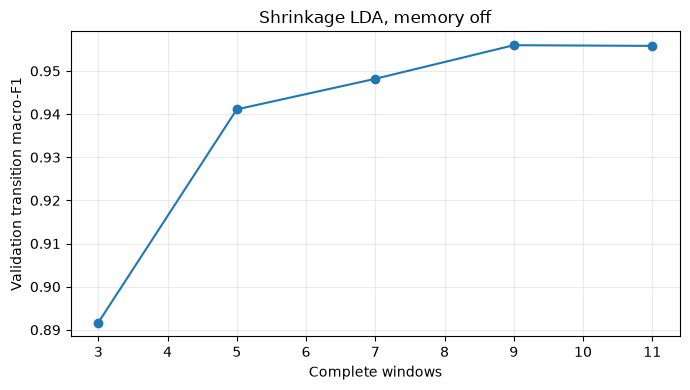

In [6]:
recorded_window_folds = pd.DataFrame([
    (3, 1, 10.0943328, 0.8564632680756022, 0.9314653932734115, 0.893964330674507, 0.9323017408123792),
    (3, 2, 9.4598964, 0.8992987985773779, 0.937913585065442, 0.9186061918214099, 0.9377416860015468),
    (3, 3, 8.7027863, 0.9192516769969531, 0.9388895668299874, 0.9290706219134702, 0.9399075500770416),
    (5, 1, 26.3931997999, 0.9236464810568004, 0.9416198962078403, 0.9326331886323205, 0.9446808510638298),
    (5, 2, 13.6839702, 0.945380032438856, 0.9403373269222638, 0.9428586796805599, 0.9423820572312451),
    (5, 3, 26.1319158, 0.9542799738342213, 0.9360438225892671, 0.9451618982117441, 0.9399075500770416),
    (7, 1, 75.4874012, 0.9326608551882543, 0.9554976923375288, 0.9440792737628915, 0.9574468085106383),
    (7, 2, 43.1111689999, 0.9464983726284036, 0.9475876862419591, 0.9470430294351814, 0.9489559164733179),
    (7, 3, 37.5374135, 0.9653910849453323, 0.9376002710222787, 0.9514956779838055, 0.9414483821263482),
    (9, 1, 137.0812905, 0.9494984402943367, 0.9694772292432288, 0.9594878347687827, 0.9705996131528046),
    (9, 2, 77.9315242, 0.9530221780867262, 0.9511441944559218, 0.952083186271324, 0.9524361948955916),
    (9, 3, 72.0529278, 0.9653910849453323, 0.9357345903430413, 0.9505628376441869, 0.9399075500770416),
    (11, 1, 200.2893542, 0.9441344556200072, 0.9716987825210369, 0.9579166190705221, 0.9725338491295938),
    (11, 2, 164.2876275, 0.9496276243290839, 0.95437865240451, 0.9520031383667971, 0.9547563805104409),
    (11, 3, 250.0451676, 0.9736805842634698, 0.9315477469029609, 0.9526141655832153, 0.9375963020030816),
], columns=['window', 'fold', 'elapsed_seconds', 'transition_f1', 'common_f1', 'macro_f1', 'accuracy'])

if RUN_LDA_EXPERIMENTS:
    window_results = {3: condition_results["three"]}
    window_validation = {3: three_validation}
    for window in [5, 7, 9, 11]:
        window_results[window], window_validation[window] = fit_lda_cv(
            window, keep_probabilities=True)
    window_folds = pd.concat([folds.assign(window=window)
                              for window, folds in window_results.items()], ignore_index=True)
else:
    window_folds = recorded_window_folds.copy()
window_summary = window_folds.groupby("window", as_index=False)[
    ["transition_f1", "common_f1", "macro_f1", "accuracy", "elapsed_seconds"]].mean()
window_summary = window_summary.rename(columns={"elapsed_seconds": "mean_seconds_per_fold"})
window_summary["features"] = window_summary.window * len(FEATURE_COLUMNS)
display(window_folds[["window", "fold", "transition_f1", "common_f1", "elapsed_seconds"]].round(6))
display(window_summary.round(6))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(window_summary.window, window_summary.transition_f1, marker="o")
ax.set(xlabel="Complete windows", ylabel="Validation transition macro-F1",
       title="Shrinkage LDA, memory off")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 4. Paired posture-memory comparison and practical selection

Compare memory off/on at every tested length using the same fitted models and validation probabilities. The rule is adapted from the team's MLP: only SIT_TO_LIE/STAND_TO_LIE predictions can change, using up to eight previous rows from the same participant and at least 0.75 accumulated sitting/standing probability mass. It uses no true labels or corrected-label feedback. Common-class F1 is invariant because only these two transition labels can be swapped.

Choose the shortest length within 0.005 transition F1 of the best window/memory combination, subject to common F1 being no more than 0.01 below the matching three-window memory variant. At that length prefer higher transition F1; exact ties favour memory off. Use unrounded scores. This practical rule does not establish a universal optimum or statistical equivalence.

In [7]:
recorded_memory_folds = pd.DataFrame([
    (3, False, 1, 0.8564632680756022, 0.9314653932734115, 0.893964330674507, 0.9323017408123792),
    (3, True, 1, 0.893944527445917, 0.9314653932734115, 0.9127049603596644, 0.935009671179884),
    (3, False, 2, 0.8992987985773779, 0.937913585065442, 0.9186061918214099, 0.9377416860015468),
    (3, True, 2, 0.9247845706669237, 0.937913585065442, 0.9313490778661828, 0.9392884764114462),
    (3, False, 3, 0.9192516769969531, 0.9388895668299874, 0.9290706219134702, 0.9399075500770416),
    (3, True, 3, 0.9402511453648424, 0.9388895668299874, 0.939570356097415, 0.9410631741140215),
    (5, False, 1, 0.9236464810568004, 0.9416198962078403, 0.9326331886323205, 0.9446808510638298),
    (5, True, 1, 0.9607447066199909, 0.9416198962078403, 0.9511823014139157, 0.9473887814313346),
    (5, False, 2, 0.945380032438856, 0.9403373269222638, 0.9428586796805599, 0.9423820572312451),
    (5, True, 2, 0.945380032438856, 0.9403373269222638, 0.9428586796805599, 0.9423820572312451),
    (5, False, 3, 0.9542799738342213, 0.9360438225892671, 0.9451618982117441, 0.9399075500770416),
    (5, True, 3, 0.974369832627546, 0.9360438225892671, 0.9552068276084064, 0.9410631741140215),
    (7, False, 1, 0.9326608551882543, 0.9554976923375288, 0.9440792737628915, 0.9574468085106383),
    (7, True, 1, 0.9710814327773959, 0.9554976923375288, 0.9632895625574621, 0.9601547388781432),
    (7, False, 2, 0.9464983726284036, 0.9475876862419591, 0.9470430294351814, 0.9489559164733179),
    (7, True, 2, 0.9530221780867262, 0.9475876862419591, 0.9503049321643428, 0.9493426140757927),
    (7, False, 3, 0.9653910849453323, 0.9376002710222787, 0.9514956779838055, 0.9414483821263482),
    (7, True, 3, 0.985480943738657, 0.9376002710222787, 0.9615406073804679, 0.9426040061633282),
    (9, False, 1, 0.9494984402943367, 0.9694772292432288, 0.9594878347687827, 0.9705996131528046),
    (9, True, 1, 0.9710814327773959, 0.9694772292432288, 0.9702793310103122, 0.972147001934236),
    (9, False, 2, 0.9530221780867262, 0.9511441944559218, 0.952083186271324, 0.9524361948955916),
    (9, True, 2, 0.9530221780867262, 0.9511441944559218, 0.952083186271324, 0.9524361948955916),
    (9, False, 3, 0.9653910849453323, 0.9357345903430413, 0.9505628376441869, 0.9399075500770416),
    (9, True, 3, 0.985480943738657, 0.9357345903430413, 0.9606077670408492, 0.9410631741140215),
    (11, False, 1, 0.9441344556200072, 0.9716987825210369, 0.9579166190705221, 0.9725338491295938),
    (11, True, 1, 0.9657174481030664, 0.9716987825210369, 0.9687081153120515, 0.9740812379110252),
    (11, False, 2, 0.9496276243290839, 0.95437865240451, 0.9520031383667971, 0.9547563805104409),
    (11, True, 2, 0.9561514297874064, 0.95437865240451, 0.9552650410959583, 0.9551430781129157),
    (11, False, 3, 0.9736805842634698, 0.9315477469029609, 0.9526141655832153, 0.9375963020030816),
    (11, True, 3, 0.9940476190476191, 0.9315477469029609, 0.9627976829752899, 0.9387519260400616),
], columns=['window', 'memory', 'fold', 'transition_f1', 'common_f1', 'macro_f1', 'accuracy'])

if RUN_LDA_EXPERIMENTS:
    memory_rows = []
    for window, validation in window_validation.items():
        for item in validation:
            va = item["rows"]
            probabilities = item["probabilities"]
            np.testing.assert_array_equal(item["classes"], LABELS)
            plain = LABELS[probabilities.argmax(axis=1)]
            adjusted = posture_memory(probabilities, groups_train[va])
            changed = plain != adjusted
            assert np.isin(plain[changed], [9, 11]).all()
            assert np.isin(adjusted[changed], [9, 11]).all()
            for memory, prediction in [(False, plain), (True, adjusted)]:
                memory_rows.append({"window": window, "memory": memory, "fold": item["fold"],
                                    **scores(y_train[va], prediction)})
    memory_folds = pd.DataFrame(memory_rows)
else:
    memory_folds = recorded_memory_folds.copy()
memory_summary = memory_folds.groupby(["window", "memory"], as_index=False)[
    ["transition_f1", "common_f1", "macro_f1", "accuracy"]].mean()
for window in [3, 5, 7, 9, 11]:
    pair = memory_folds.loc[memory_folds.window == window].pivot(
        index="fold", columns="memory", values="common_f1")
    np.testing.assert_array_equal(pair[False], pair[True])
memory_comparison = memory_summary.pivot(index="window", columns="memory", values="transition_f1")
memory_comparison = memory_comparison.rename(columns={False: "Memory off", True: "Memory on"})
memory_comparison["Change"] = memory_comparison["Memory on"] - memory_comparison["Memory off"]
display(memory_folds[["window", "memory", "fold", "transition_f1", "common_f1"]].round(6))
display(memory_comparison.rename_axis(columns=None).round(6))

,window,memory,fold,transition_f1,common_f1
0,3,False,1,0.856463,0.931465
1,3,True,1,0.893945,0.931465
2,3,False,2,0.899299,0.937914
3,3,True,2,0.924785,0.937914
4,3,False,3,0.919252,0.938890
5,3,True,3,0.940251,0.938890
6,5,False,1,0.923646,0.941620
7,5,True,1,0.960745,0.941620
8,5,False,2,0.945380,0.940337
9,5,True,2,0.945380,0.940337


,Memory off,Memory on,Change
window,,,
3,0.891671,0.919660,0.027989
5,0.941102,0.960165,0.019063
7,0.948183,0.969862,0.021678
9,0.955971,0.969862,0.013891
11,0.955814,0.971972,0.016158


In [8]:
selected_windows = {}
lda_peak = memory_summary.transition_f1.max()
lda_three_common = memory_summary.loc[memory_summary.window == 3].set_index("memory").common_f1
lda_eligible = memory_summary[
    (lda_peak - memory_summary.transition_f1 <= 0.005) &
    (memory_summary.common_f1 >= memory_summary.memory.map(lda_three_common) - 0.01)]
if lda_eligible.empty:
    raise ValueError("No LDA configuration meets the validation tolerances.")
lda_chosen = lda_eligible.sort_values(
    ["window", "transition_f1", "memory"], ascending=[True, False, True]).iloc[0]
selected_windows["lda"] = int(lda_chosen.window)
selected_lda_memory = bool(lda_chosen.memory)
lda_later = int(memory_summary.loc[
    (memory_summary.memory == selected_lda_memory) &
    (memory_summary.window > selected_windows["lda"]), "window"].nunique())

display(pd.DataFrame([{
    "Model": "Shrinkage LDA + memory" if selected_lda_memory else "Shrinkage LDA",
    "Windows": selected_windows["lda"], "Transition F1": lda_chosen.transition_f1,
    "Common F1": lda_chosen.common_f1, "Peak transition F1": lda_peak,
    "Longer lengths checked": lda_later,
}]).round(6))
if not RUN_LDA_EXPERIMENTS:
    assert selected_windows["lda"] == 7 and selected_lda_memory is True

,Model,Windows,Transition F1,Common F1,Peak transition F1,Longer lengths checked
0,Shrinkage LDA + memory,7,0.969862,0.946895,0.971972,2


The recorded results select **seven windows with posture memory**, with validation transition macro-F1 **0.9698615182** and common-class macro-F1 **0.9468952165**. Eleven windows reaches the highest measured transition score, **0.9719721656**; seven is the shortest eligible length. Nine and eleven supply two longer comparisons, rather than proof of a statistical plateau.

These are pre-PCA validation results, not official-test scores. The raw memory-off runtimes above are not a substitute for a fresh memory-on baseline in a later PCA timing comparison.

## 5. PCA quality and runtime comparison

Freeze the pre-PCA choice at seven windows with posture memory, automatic shrinkage, equal priors, no sample weighting and no oversampling. Compare raw 3,927 features with PCA-200, PCA-400 and PCA-500 on the same three participant folds. StandardScaler and randomized PCA (seed 42) are fitted on training-fold rows only. Timing includes scaling, PCA where applicable, model fitting and memory-on prediction; it excludes data loading, shared context construction, scoring and checkpoint writing.

Before fitting, fix this selection rule: a PCA candidate must lose no more than **0.005 in both transition and common-class mean F1** versus a fresh raw memory-on baseline, and reduce mean total time per fold. Repeat qualifying comparisons once with the same folds and machine, reversing representation order and timing raw last. Retain a candidate only if it meets both quality tolerances and is faster in both runs. If several pass, choose the smallest mean time across the two runs; break exact timing ties by representation name. Otherwise retain raw. Section 4 remains the pre-PCA window/memory experiment.

Set `RUN_LDA_PCA=True` to execute this new comparison independently of the earlier experiment flag. With False, display the recorded PCA results. An optional `PCA_RESULTS_DIR` can hold per-fold checkpoints; None requires no additional files. No test data is loaded or evaluated.

In [9]:
from sklearn.decomposition import PCA
import json

RUN_LDA_PCA = False
PCA_RESULTS_DIR = None
if PCA_RESULTS_DIR is not None:
    PCA_RESULTS_DIR = Path(PCA_RESULTS_DIR)
    PCA_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

assert selected_windows["lda"] == 7 and selected_lda_memory


In [10]:
def prepare(x_train, x_eval, representation="raw"):
    scaler = StandardScaler()
    train_scaled = scaler.fit_transform(x_train)
    eval_scaled = scaler.transform(x_eval)
    if representation.startswith("pca"):
        pca = PCA(n_components=int(representation[3:]), svd_solver="randomized", random_state=42)
        train_scaled = pca.fit_transform(train_scaled)
        eval_scaled = pca.transform(eval_scaled)
    return train_scaled.astype(np.float32), eval_scaled.astype(np.float32)


def benchmark_lda_cv(representation="raw", run=1):
    features = add_context(x_train, groups_train, selected_windows["lda"])
    rows = []
    for fold, (tr, va) in enumerate(SPLITS, 1):
        assert set(groups_train[tr]).isdisjoint(groups_train[va])
        fold_x = features[tr]
        started = perf_counter()
        fit_x, val_x = prepare(fold_x, features[va], representation)
        model = LinearDiscriminantAnalysis(
            solver="lsqr", shrinkage="auto", priors=np.full(12, 1 / 12))
        model.fit(fit_x, y_train[tr])
        np.testing.assert_array_equal(model.classes_, LABELS)
        probabilities = model.predict_proba(val_x)
        prediction = posture_memory(probabilities, groups_train[va])
        elapsed = perf_counter() - started
        rows.append({"run": run, "representation": representation, "fold": fold,
                     "elapsed_seconds": elapsed, **scores(y_train[va], prediction)})
        if PCA_RESULTS_DIR is not None:
            np.savez_compressed(PCA_RESULTS_DIR / f"run-{run}-{representation}-fold-{fold}.npz",
                                probabilities=probabilities, predictions=prediction,
                                validation_rows=va, classes=model.classes_)
            (PCA_RESULTS_DIR / f"run-{run}-{representation}.json").write_text(
                json.dumps(rows, default=lambda value: value.tolist()), encoding="utf-8")
        print(f"PCA benchmark run {run}, {representation}, fold {fold}: "
              f"transition F1={rows[-1]['transition_f1']:.6f}, {elapsed:.2f} s", flush=True)
    return pd.DataFrame(rows)


def summarize_pca(folds):
    return folds.groupby(["run", "representation"], as_index=False)[
        ["transition_f1", "common_f1", "macro_f1", "accuracy", "elapsed_seconds"]].mean().rename(
            columns={"elapsed_seconds": "mean_seconds_per_fold"})


def qualifying_pca(summary, run=1):
    current = summary.loc[summary.run == run]
    raw = current.loc[current.representation == "raw"].iloc[0]
    return current.loc[
        (current.representation != "raw") &
        (current.transition_f1 >= raw.transition_f1 - 0.005) &
        (current.common_f1 >= raw.common_f1 - 0.005) &
        (current.mean_seconds_per_fold < raw.mean_seconds_per_fold), "representation"].tolist()


In [11]:
# Recorded from the executed PCA comparison.
recorded_pca_folds = pd.DataFrame([
    (1, 'raw', 1, 37.378726099967025, 0.9710814327773959, 0.9554976923375288, 0.9632895625574621, 0.9601547388781432),
    (1, 'raw', 2, 34.13772450003307, 0.9530221780867262, 0.9475876862419591, 0.9503049321643428, 0.9493426140757927),
    (1, 'raw', 3, 34.428939599893056, 0.985480943738657, 0.9376002710222787, 0.9615406073804679, 0.9426040061633282),
    (1, 'pca200', 1, 1.2076726999366656, 0.9049256540498484, 0.9129671233123527, 0.9089463886811004, 0.9156673114119923),
    (1, 'pca200', 2, 1.1780676000053063, 0.8729316201579483, 0.9140947400738253, 0.8935131801158868, 0.9149265274555298),
    (1, 'pca200', 3, 1.1962179000256583, 0.8355289073771326, 0.9120228171272043, 0.8737758622521685, 0.9083204930662557),
    (1, 'pca400', 1, 1.5729815000668168, 0.9562265777735847, 0.9299531627634988, 0.9430898702685416, 0.935009671179884),
    (1, 'pca400', 2, 1.5891168999951333, 0.9281080255068533, 0.9250191171758314, 0.9265635713413422, 0.9292343387470998),
    (1, 'pca400', 3, 1.5577335000270978, 0.9043536565986985, 0.9191811107940886, 0.9117673836963935, 0.9194915254237288),
    (1, 'pca500', 1, 1.8719206000678241, 0.9683696806287618, 0.9357743252702345, 0.9520720029494981, 0.9396518375241779),
    (1, 'pca500', 2, 1.9424075999995694, 0.9236995340400913, 0.9257376629099764, 0.9247185984750339, 0.9292343387470998),
    (1, 'pca500', 3, 1.9838681999826804, 0.9627535463643819, 0.9266905033643466, 0.9447220248643641, 0.9291217257318952),
], columns=['run', 'representation', 'fold', 'elapsed_seconds', 'transition_f1', 'common_f1', 'macro_f1', 'accuracy'])

if RUN_LDA_PCA:
    pca_results = [benchmark_lda_cv(representation, run=1)
                   for representation in ["raw", "pca200", "pca400", "pca500"]]
    pca_folds = pd.concat(pca_results, ignore_index=True)
    initial = summarize_pca(pca_folds)
    candidates = qualifying_pca(initial)
    if candidates:
        for representation in [*reversed(candidates), "raw"]:
            pca_results.append(benchmark_lda_cv(representation, run=2))
        pca_folds = pd.concat(pca_results, ignore_index=True)
else:
    pca_folds = recorded_pca_folds.copy()

pca_summary = summarize_pca(pca_folds)
display(pca_folds[["run", "representation", "fold", "transition_f1",
                   "common_f1", "elapsed_seconds"]].round(6))
display(pca_summary.round(6))


PCA benchmark run 1, raw, fold 1: transition F1=0.971081, 37.38 s


PCA benchmark run 1, raw, fold 2: transition F1=0.953022, 34.14 s


PCA benchmark run 1, raw, fold 3: transition F1=0.985481, 34.43 s


PCA benchmark run 1, pca200, fold 1: transition F1=0.904926, 1.21 s


PCA benchmark run 1, pca200, fold 2: transition F1=0.872932, 1.18 s


...

PCA benchmark run 1, pca500, fold 1: transition F1=0.968370, 1.87 s


PCA benchmark run 1, pca500, fold 2: transition F1=0.923700, 1.94 s


PCA benchmark run 1, pca500, fold 3: transition F1=0.962754, 1.98 s


,run,representation,fold,transition_f1,common_f1,elapsed_seconds
0,1,raw,1,0.971081,0.955498,37.378726
1,1,raw,2,0.953022,0.947588,34.137725
2,1,raw,3,0.985481,0.937600,34.428940
3,1,pca200,1,0.904926,0.912967,1.207673
4,1,pca200,2,0.872932,0.914095,1.178068
5,1,pca200,3,0.835529,0.912023,1.196218
6,1,pca400,1,0.956227,0.929953,1.572982
7,1,pca400,2,0.928108,0.925019,1.589117
8,1,pca400,3,0.904354,0.919181,1.557734
9,1,pca500,1,0.968370,0.935774,1.871921


,run,representation,transition_f1,common_f1,macro_f1,accuracy,mean_seconds_per_fold
0,1,pca200,0.871129,0.913028,0.892078,0.912971,1.193986
1,1,pca400,0.929563,0.924718,0.927140,0.927912,1.573277
2,1,pca500,0.951608,0.929401,0.940504,0.932669,1.932732
3,1,raw,0.969862,0.946895,0.958378,0.950700,35.315130


In [12]:
pca_initial = pca_summary.loc[pca_summary.run == 1].copy()
raw_reference = pca_initial.loc[pca_initial.representation == "raw"].iloc[0]
pca_initial["transition_change"] = pca_initial.transition_f1 - raw_reference.transition_f1
pca_initial["common_change"] = pca_initial.common_f1 - raw_reference.common_f1
pca_initial["time_saved_pct"] = 100 * (1 - pca_initial.mean_seconds_per_fold /
                                        raw_reference.mean_seconds_per_fold)
display(pca_initial.round(6))

paired_rows = []
for representation in qualifying_pca(pca_summary, run=1):
    for run in [1, 2]:
        current = pca_summary.loc[pca_summary.run == run].set_index("representation")
        if representation not in current.index or "raw" not in current.index:
            continue
        raw, candidate = current.loc["raw"], current.loc[representation]
        paired_rows.append({"representation": representation, "run": run,
                            "raw_seconds": raw.mean_seconds_per_fold,
                            "pca_seconds": candidate.mean_seconds_per_fold,
                            "transition_change": candidate.transition_f1 - raw.transition_f1,
                            "common_change": candidate.common_f1 - raw.common_f1})
pca_paired = pd.DataFrame(paired_rows, columns=["representation", "run", "raw_seconds",
                                              "pca_seconds", "transition_change", "common_change"])
if not pca_paired.empty:
    pca_paired["time_saved_pct"] = 100 * (1 - pca_paired.pca_seconds / pca_paired.raw_seconds)
    pca_paired["pass"] = ((pca_paired.transition_change >= -0.005) &
                          (pca_paired.common_change >= -0.005) &
                          (pca_paired.time_saved_pct > 0))
    display(pca_paired.round(6))

passing = [representation for representation, group in pca_paired.groupby("representation")
           if set(group.run) == {1, 2} and group["pass"].all()]
selected_lda_representation = "raw"
if passing:
    selected_lda_representation = pca_paired.loc[pca_paired.representation.isin(passing)].groupby(
        "representation").pca_seconds.mean().rename("mean_seconds").reset_index().sort_values(
            ["mean_seconds", "representation"]).representation.iat[0]
print("Selected LDA representation:", selected_lda_representation)


,run,representation,transition_f1,common_f1,macro_f1,accuracy,mean_seconds_per_fold,transition_change,common_change,time_saved_pct
0,1,pca200,0.871129,0.913028,0.892078,0.912971,1.193986,-0.098733,-0.033867,96.619052
1,1,pca400,0.929563,0.924718,0.927140,0.927912,1.573277,-0.040299,-0.022177,95.545033
2,1,pca500,0.951608,0.929401,0.940504,0.932669,1.932732,-0.018254,-0.017494,94.527184
3,1,raw,0.969862,0.946895,0.958378,0.950700,35.315130,0.000000,0.000000,0.000000


Selected LDA representation: raw


For **seven-window LDA with posture memory**, the fresh raw baseline has validation transition F1 **0.9699** and common F1 **0.9469**, taking **35.32 seconds per fold**. PCA-200/400/500 reach transition F1 **0.8711**, **0.9296**, **0.9516** respectively. Every tested PCA setting exceeds the F1-loss tolerances, so no timing repeat is needed and **LDA retains raw features**. PCA preserves high-variance directions rather than directly optimising rare-transition recognition, so dimensionality reduction is not guaranteed to preserve these class distinctions.

## 6. Fixed LDA configurations: descriptive test comparison

Keep the validation-selected pipeline fixed: **seven windows, raw features, automatic shrinkage, equal priors, posture memory, no sample weighting or oversampling**. Fit it once on all training participants and evaluate the official test participants. Also fit single-window and three-window LDA, both raw and memory off, to complete the baseline and controlled context comparison. These test results do not select or retune the configurations. The project test set was previously inspected during development; this is a descriptive comparison.

Set `RUN_LDA_TEST=True` to reproduce these three fits independently of the earlier experiment flags. The default False displays the recorded results and reconstructs selected-pipeline metrics from the saved predictions. Retain those predictions for later error analysis without another fit. `LDA_TEST_RESULTS_DIR=None` requires no additional checkpoint files.

In [13]:
RUN_LDA_TEST = False
LDA_TEST_RESULTS_DIR = None
if LDA_TEST_RESULTS_DIR is not None:
    LDA_TEST_RESULTS_DIR = Path(LDA_TEST_RESULTS_DIR)
    LDA_TEST_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

assert selected_windows["lda"] == 7 and selected_lda_memory
assert selected_lda_representation == "raw"
test_df = pd.read_csv(ROOT / "our approach/wrangled data/hapt_test.csv")
assert list(test_df.columns) == list(train_df.columns)
x_test, y_test, groups_test = arrays(test_df)
assert x_test.shape == (3162, 561)
assert len(np.unique(groups_test)) == 9
assert set(groups_train).isdisjoint(groups_test)
assert len(np.unique(groups_test)) == 1 + np.count_nonzero(groups_test[1:] != groups_test[:-1])


In [14]:
def fit_lda_test(context="single", lda_memory=False, representation="raw"):
    train_features = add_context(x_train, groups_train, context)
    test_features = add_context(x_test, groups_test, context)
    fit_x, eval_x = prepare(train_features, test_features, representation)
    model = LinearDiscriminantAnalysis(
        solver="lsqr", shrinkage="auto", priors=np.full(12, 1 / 12))
    model.fit(fit_x, y_train)
    np.testing.assert_array_equal(model.classes_, LABELS)
    probabilities = model.predict_proba(eval_x)
    if lda_memory:
        prediction = posture_memory(probabilities, groups_test)
    else:
        prediction = model.predict(eval_x)
        np.testing.assert_array_equal(prediction, LABELS[probabilities.argmax(axis=1)])
    return {**scores(y_test, prediction), "predictions": prediction,
            "probabilities": probabilities}


TEST_METRICS = ["transition_f1", "transition_recall", "common_f1", "macro_f1", "accuracy"]


In [15]:
# Recorded from the executed fixed-pipeline comparison.
recorded_test_summary = pd.DataFrame([
    ('single', 0.7829131652661064, 0.8186776594695849, 0.9490817568735209, 0.8659974610698137, 0.9399114484503479),
    ('three', 0.8992016935598716, 0.908849459671147, 0.9682942660967565, 0.933747979828314, 0.9636306135357369),
    ('selected', 0.9779207537466825, 0.9736052230876245, 0.9787031818995543, 0.9783119678231184, 0.9781783681214421),
], columns=['pipeline', 'transition_f1', 'transition_recall', 'common_f1', 'macro_f1', 'accuracy'])
recorded_selected_predictions = np.array([
    5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 7, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 5, 8, 5, 5, 5, 5, 5, 5, 5, 5, 5,
    5, 5, 5, 5, 5, 5, 5, 11, 11, 11, 11, 11, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 10, 10, 10, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 9, 9, 6,
    6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 12, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
    1, 1, 1, 3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3,
    3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 7, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 8, 5, 5, 5, 5,
    5, 5, 5, 5, 5, 5, 5, 5, 11, 11, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 10, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 9, 6, 6, 6, 6, 6, 6,
    6, 6, 6, 6, 6, 6, 6, 6, 12, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 3,
    3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2,
    2, 2, 2, 2, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 7, 7, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 8, 5, 5, 5, 5, 5,
    5, 5, 5, 5, 5, 5, 5, 5, 11, 11, 11, 11, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 10, 10, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
    4, 9, 9, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 12, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
    1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2,
    2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 4, 4, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 7, 4, 4, 4, 4,
    4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 8, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 11, 11, 11, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 10, 10, 4,
    4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 9, 9, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 12, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
    1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2,
    2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 5, 4, 4, 4, 5, 4, 4, 5, 5, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 5,
    5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 11, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 10, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
    4, 4, 4, 4, 4, 9, 9, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 12, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
    1, 1, 1, 1, 1, 1, 1, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3,
    3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 4, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 7, 4, 4, 4, 4, 4, 4, 4, 4, 5, 4, 4, 4, 4, 4, 5,
    5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 11, 11, 11, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 10, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
    4, 4, 9, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 12, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
    1, 1, 1, 1, 1, 1, 1, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3,
    3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 7, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 5, 5, 5, 5,
    5, 5, 5, 5, 5, 5, 5, 5, 11, 11, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 10, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 9, 6,
    6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
    1, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2,
    2, 2, 2, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 4, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5,
    5, 5, 11, 11, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 5, 5, 9, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6,
    6, 6, 6, 6, 6, 6, 6, 12, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 3, 3, 3, 3, 3,
    2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 1, 5, 5, 5,
    5, 5, 5, 5, 5, 5, 5, 5, 7, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 11, 11, 6,
    6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 10, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 5, 4, 4, 5, 4, 4, 9, 6, 6, 6, 6, 6, 6, 6, 6,
    6, 6, 6, 6, 6, 12, 12, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 3, 3, 3, 3, 3,
    3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2,
    2, 2, 2, 2, 2, 2, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 7, 4, 4, 4, 4, 4, 4, 4, 4, 4, 5,
    8, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 11, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 10, 4, 4, 4, 4, 4, 4,
    4, 4, 5, 5, 4, 4, 4, 4, 4, 4, 4, 9, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 12, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
    1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2,
    2, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 7, 4, 4, 4, 4, 4, 4,
    4, 4, 4, 4, 4, 4, 4, 8, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 4, 11, 11, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 10, 4, 4,
    4, 4, 4, 4, 4, 4, 4, 4, 4, 9, 9, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 12, 12, 12, 1, 1, 1, 1, 1, 1, 1, 1,
    1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2,
    2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
    5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 7, 7, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 8, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5,
    5, 5, 5, 11, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 10, 10, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 9, 9, 6, 6, 6,
    6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 12, 12, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
    1, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 2, 2, 2,
    2, 2, 2, 2, 2, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 7, 7, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
    4, 4, 4, 4, 4, 8, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 11, 11, 11, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6,
    6, 6, 6, 6, 6, 6, 6, 10, 10, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 9, 9, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6,
    6, 6, 6, 6, 6, 6, 6, 6, 12, 12, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
    3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3,
    3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 7, 7, 4, 4, 4,
    4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 8, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 11, 11, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6,
    6, 6, 6, 6, 6, 6, 6, 10, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 9, 9, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6,
    6, 6, 6, 12, 12, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 3, 3, 3, 3, 3, 3, 3,
    3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 2, 2, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2,
    2, 2, 2, 2, 2, 2, 2, 2, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 7, 7, 4, 4, 4, 4, 4, 4, 4, 4,
    4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 8, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 11, 11, 11, 11, 11, 6, 6, 6, 6, 6,
    6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 10, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 9, 9, 9, 6, 6, 6, 6, 6, 6, 6, 6,
    6, 6, 6, 6, 6, 6, 12, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 3, 3, 3, 3, 3,
    3, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2,
    2, 2, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 7, 7, 5, 5, 5, 5, 5, 4, 4, 4, 4, 4, 4, 5, 5, 5, 5,
    5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 11, 11, 11, 11, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 10,
    10, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 9, 9, 9, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 12,
    1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2,
    3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 5, 5, 5, 5, 5, 5, 5, 5,
    5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 7, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 5, 5, 5, 5, 5, 5, 5, 5, 5,
    5, 5, 5, 5, 5, 5, 5, 5, 7, 11, 4, 11, 11, 11, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 10, 10, 4, 4, 4, 4, 4, 4,
    4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 9, 9, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 10, 12, 12, 1, 1, 1, 1, 1, 1,
    1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3,
    3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 5,
    5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 7, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 5, 5, 5, 5, 5, 5,
    5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 11, 11, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 10, 4, 4, 4, 4, 4, 4, 4, 4,
    4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 9, 9, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 12, 12, 1, 1, 1, 1, 1, 1,
    1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2,
    2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2,
    2, 2,
], dtype=np.int64)

if RUN_LDA_TEST:
    test_results = {}
    for name, context, memory in [("single", "single", False),
                                  ("three", "bidirectional", False),
                                  ("selected", selected_windows["lda"], selected_lda_memory)]:
        result = fit_lda_test(context, lda_memory=memory,
                              representation=selected_lda_representation)
        test_results[name] = result
        if LDA_TEST_RESULTS_DIR is not None:
            np.savez_compressed(LDA_TEST_RESULTS_DIR / f"test-{name}.npz",
                                predictions=result["predictions"],
                                probabilities=result["probabilities"],
                                truth=y_test, participants=groups_test)
            (LDA_TEST_RESULTS_DIR / f"test-{name}.json").write_text(
                json.dumps({key: value for key, value in result.items()
                            if key not in ["predictions", "probabilities"]},
                           default=lambda value: value.tolist()), encoding="utf-8")
        print(f"LDA test pipeline {name} completed: "
              f"transition F1={result['transition_f1']:.6f}", flush=True)
    test_summary = pd.DataFrame([
        {"pipeline": name, **{metric: result[metric] for metric in TEST_METRICS}}
        for name, result in test_results.items()])
    selected_test_predictions = test_results["selected"]["predictions"].copy()
else:
    test_summary = recorded_test_summary.copy()
    selected_test_predictions = recorded_selected_predictions.copy()

display(test_summary.round(6))
selected_test_score = scores(y_test, selected_test_predictions)
selected_record = test_summary.set_index("pipeline").loc["selected"]
for metric in TEST_METRICS:
    np.testing.assert_allclose(selected_test_score[metric], selected_record[metric], rtol=0, atol=1e-15)
context_test_change = test_summary.set_index("pipeline").loc["three", ["transition_f1", "common_f1"]] -                       test_summary.set_index("pipeline").loc["single", ["transition_f1", "common_f1"]]
display(context_test_change.rename("Three-window minus single-window").to_frame().round(6))


LDA test pipeline single completed: transition F1=0.782913


LDA test pipeline three completed: transition F1=0.899202


LDA test pipeline selected completed: transition F1=0.977921


,pipeline,transition_f1,transition_recall,common_f1,macro_f1,accuracy
0,single,0.782913,0.818678,0.949082,0.865997,0.939911
1,three,0.899202,0.908849,0.968294,0.933748,0.963631
2,selected,0.977921,0.973605,0.978703,0.978312,0.978178


,Three-window minus single-window
transition_f1,0.116289
common_f1,0.019213


The selected seven-window, memory-on raw LDA has descriptive test transition F1 **0.9779**, common F1 **0.9787**, overall macro-F1 **0.9783** and accuracy **0.9782**. Single-window memory-off transition F1 is **0.7829**; three-window memory-off reaches **0.8992**, a change of **+0.1163**. No configuration was changed after these evaluations. The selected predictions are retained above for subsequent error analysis without another fit.

### Selected LDA: per-class test recall

Compute the correct-window counts and recall from the selected test predictions retained in Section 6. This requires no model fitting. The shared notebook compares these values with its recorded MLP class results.

In [16]:
activity_names = test_df[["activity_id", "activity_label"]].drop_duplicates().set_index(
    "activity_id").activity_label
lda_test_class_recall = pd.DataFrame({
    "activity_id": LABELS,
    "activity": activity_names.reindex(LABELS).to_numpy(),
    "support": selected_test_score["support"],
    "correct": [int(np.count_nonzero((y_test == label) &
                                     (selected_test_predictions == label))) for label in LABELS],
    "recall": selected_test_score["per_class_recall"],
})
np.testing.assert_allclose(lda_test_class_recall.correct / lda_test_class_recall.support,
                           lda_test_class_recall.recall, rtol=0, atol=1e-15)
display(lda_test_class_recall.round(6))

,activity_id,activity,support,correct,recall
0,1,WALKING,496,495,0.997984
1,2,WALKING_UPSTAIRS,471,470,0.997877
2,3,WALKING_DOWNSTAIRS,420,407,0.969048
3,4,SITTING,508,472,0.929134
4,5,STANDING,556,544,0.978417
5,6,LAYING,545,544,0.998165
6,7,STAND_TO_SIT,23,22,0.956522
7,8,SIT_TO_STAND,10,10,1.000000
8,9,SIT_TO_LIE,32,32,1.000000
9,10,LIE_TO_SIT,25,25,1.000000


### LDA transition metrics, confusion and individual errors

Reuse the selected predictions to compute all-class confusion counts and the six-transition precision/recall/F1 table. Include every misclassification with a true or predicted transition, so common-to-transition false positives remain visible. Test row IDs are zero-based CSV row positions excluding the header. No model is fitted.

In [17]:
from sklearn.metrics import confusion_matrix

lda_test_confusion = confusion_matrix(y_test, selected_test_predictions, labels=LABELS)
lda_transition_metrics = pd.DataFrame({
    "activity_id": LABELS,
    "activity": activity_names.reindex(LABELS).to_numpy(),
    "support": selected_test_score["support"],
    "precision": selected_test_score["per_class_precision"],
    "recall": selected_test_score["per_class_recall"],
    "f1": selected_test_score["per_class_f1"],
}).loc[lambda frame: frame.activity_id >= 7].reset_index(drop=True)

wrong = np.flatnonzero(y_test != selected_test_predictions)
lda_all_test_errors = pd.DataFrame({
    "test_row": wrong,
    "participant": groups_test[wrong],
    "actual_id": y_test[wrong],
    "predicted_id": selected_test_predictions[wrong],
})
lda_all_test_errors["actual"] = lda_all_test_errors.actual_id.map(activity_names)
lda_all_test_errors["predicted"] = lda_all_test_errors.predicted_id.map(activity_names)
lda_transition_cases = lda_all_test_errors.loc[
    (lda_all_test_errors.actual_id >= 7) | (lda_all_test_errors.predicted_id >= 7)].copy()
# Adjacent true labels are used only for post-hoc diagnosis, not prediction.
lda_transition_cases["previous_actual"] = [
    activity_names[y_test[row - 1]] if row > 0 and groups_test[row - 1] == groups_test[row]
    else "Participant boundary" for row in lda_transition_cases.test_row]
lda_transition_cases["next_actual"] = [
    activity_names[y_test[row + 1]] if row + 1 < len(y_test) and groups_test[row + 1] == groups_test[row]
    else "Participant boundary" for row in lda_transition_cases.test_row]
lda_error_counts = {
    "total_errors": len(wrong),
    "transition_support": int(np.count_nonzero(y_test >= 7)),
    "correct_transitions": int(np.count_nonzero((y_test >= 7) & (y_test == selected_test_predictions))),
    "true_transition_errors": int(np.count_nonzero((y_test >= 7) & (y_test != selected_test_predictions))),
    "common_to_transition": int(np.count_nonzero((y_test <= 6) & (selected_test_predictions >= 7))),
    "transition_to_common": int(np.count_nonzero((y_test >= 7) & (selected_test_predictions <= 6))),
    "transition_to_transition": int(np.count_nonzero(
        (y_test >= 7) & (selected_test_predictions >= 7) & (y_test != selected_test_predictions))),
}
display(lda_transition_metrics.round(4))
display(lda_transition_cases.reset_index(drop=True))
display(pd.Series(lda_error_counts, name="windows").to_frame())

,activity_id,activity,support,precision,recall,f1
0,7,STAND_TO_SIT,23,0.9565,0.9565,0.9565
1,8,SIT_TO_STAND,10,1.0000,1.0000,1.0000
2,9,SIT_TO_LIE,32,1.0000,1.0000,1.0000
3,10,LIE_TO_SIT,25,0.9615,1.0000,0.9804
4,11,STAND_TO_LIE,49,0.9792,0.9592,0.9691
5,12,LIE_TO_STAND,27,1.0000,0.9259,0.9615


,test_row,participant,actual_id,predicted_id,actual,predicted,previous_actual,next_actual
0,1163,10,6,11,LAYING,STAND_TO_LIE,STAND_TO_LIE,LAYING
1,1989,18,7,4,STAND_TO_SIT,SITTING,STAND_TO_SIT,SITTING
2,2808,24,11,7,STAND_TO_LIE,STAND_TO_SIT,STANDING,STAND_TO_LIE
3,2810,24,11,4,STAND_TO_LIE,SITTING,STAND_TO_LIE,STAND_TO_LIE
4,2871,24,12,10,LIE_TO_STAND,LIE_TO_SIT,LAYING,LIE_TO_STAND
5,2874,24,12,1,LIE_TO_STAND,WALKING,LIE_TO_STAND,WALKING


,windows
total_errors,69
transition_support,166
correct_transitions,161
true_transition_errors,5
common_to_transition,1
transition_to_common,3
transition_to_transition,2


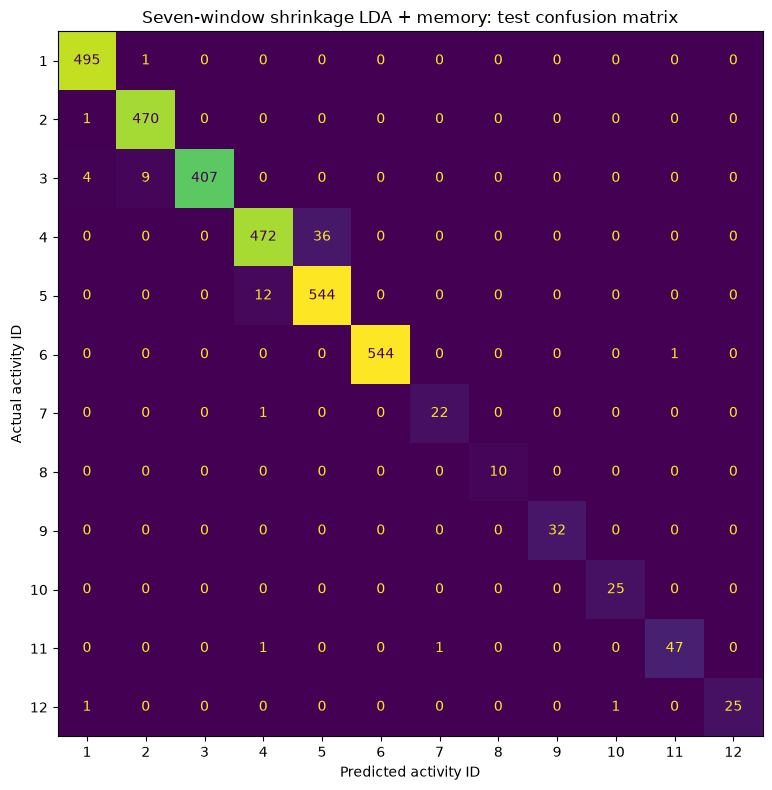

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(lda_test_confusion, display_labels=LABELS).plot(
    ax=ax, colorbar=False, values_format="d")
ax.set(title="Seven-window shrinkage LDA + memory: test confusion matrix",
       xlabel="Predicted activity ID", ylabel="Actual activity ID")
plt.tight_layout()
plt.show()

#### Interpretation and future improvements

**Remaining transition weaknesses.** LDA correctly classifies 161 of the 166 true transition windows. STAND_TO_SIT has the lowest transition F1 (0.9565), while LIE_TO_STAND has the lowest recall (25/27, or 92.59%). SIT_TO_STAND and SIT_TO_LIE have perfect precision and recall in this test sample, based on only 10 and 32 windows respectively. LIE_TO_SIT illustrates why recall alone is insufficient: all 25 true windows are recognised, but the LIE_TO_STAND false positive lowers its precision to 0.9615 and F1 to 0.9804. The LAYING-to-STAND_TO_LIE error also lowers transition precision despite originating from a common activity.

**Where the errors occur.** Four of the five true transition errors belong to participant 24. Rows 2808 and 2871 confuse transitions sharing the same starting posture but different destinations. Row 1989 is the last STAND_TO_SIT-labelled row before SITTING at row 1990; row 2874 is the last LIE_TO_STAND-labelled row before WALKING at row 2875. Conversely, row 1163 is the first LAYING-labelled row after STAND_TO_LIE at row 1162. These adjacent-label patterns suggest possible ambiguity around activity changes, but they do not establish a physical cause. The prepared CSV has no exact timestamps or within-participant recording IDs, so confirming motion or boundary explanations requires further inspection of the raw recordings.

**Common-activity trade-offs.** Of all 69 classification errors, 48 are SITTING/STANDING swaps and 13 are WALKING_DOWNSTAIRS windows predicted as another walking activity. These confusions account for most remaining errors even though the project prioritises rare transitions. Compared with MLP's recorded class counts, LDA misses fewer true transition windows overall (5 versus 8), but MLP recognises more LIE_TO_STAND windows (26/27 versus 25/27). Their different window lengths and imbalance treatments mean this comparison does not isolate the effect of classifier family alone.

**Future work.** The fixed memory rule only switches SIT_TO_LIE and STAND_TO_LIE predictions; it cannot correct predictions such as LIE_TO_SIT, SITTING or WALKING. Future studies could inspect the listed recordings, validate recording-aware context and additional posture cues using training participants, and collect more rare-transition examples across participants. The error cases motivate these checks; they do not justify changing the selected pipeline based on its test errors.